<a href="https://colab.research.google.com/github/yoloaryan/Deep_learning/blob/main/Deep_Learning_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# Experiment No. 2: Basic Neural Network Implementation

### **Objective:**
To apply a basic neural network using Python on the Iris dataset and interpret results.

### **Concept:**
A Neural Network consists of layers of neurons. For these experiments, we use a **Multi-Layer Perceptron (MLP)**.
- **Weight Initialization:** Random weights assigned to connections.
- **Activation Function:** ReLU (Rectified Linear Unit) for hidden layers and Softmax for the output layer (multi-class).
- **Backpropagation:** The process of updating weights based on the error using Gradient Descent.

### **Interpretation:**
We look at the **Confusion Matrix** to see if the network confuses specific flower species (Setosa, Versicolor, Virginica).

In [ ]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import pandas as pd

#1.load the dataset
iris = load_iris()
X,y = iris.data, iris.target

#view the datasets
iris_df = pd.DataFrame(X,columns=iris.feature_names)
iris_df['species'] = y
print("Iris Dataset Preview : ")
display(iris_df.head())


Iris Dataset Preview : 


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
iris_df.shape

(150, 5)

In [ ]:
#2 train test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)


In [ ]:
# 3 Multi- Layer Neural Network
#we define a hidden layer with 10 neurons
#here the relu is used for the activation and adam for the optimization


mlp =MLPClassifier(hidden_layer_sizes=(10,3),max_iter= 300,activation='relu',solver='adam',random_state=42)
mlp.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(hidden_layer_sizes=(10, 3), max_iter=300, random_state=42)

In [ ]:
#4. predict
y_pred = mlp.predict(X_test)


In [ ]:
y_pred

array([1, 0, 2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 0, 0, 0, 2, 2, 1, 2, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 2, 1, 0,
       0, 1, 2, 2, 1, 2])

In [ ]:
#5. Interpretation

print("Classification Report (Multi-layer Perceptrorn)")
print(classification_report(y_test,y_pred))

Classification Report (Multi-layer Perceptrorn)
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        19
           1       1.00      0.67      0.80        15
           2       0.76      1.00      0.86        16

    accuracy                           0.90        50
   macro avg       0.92      0.89      0.89        50
weighted avg       0.92      0.90      0.90        50



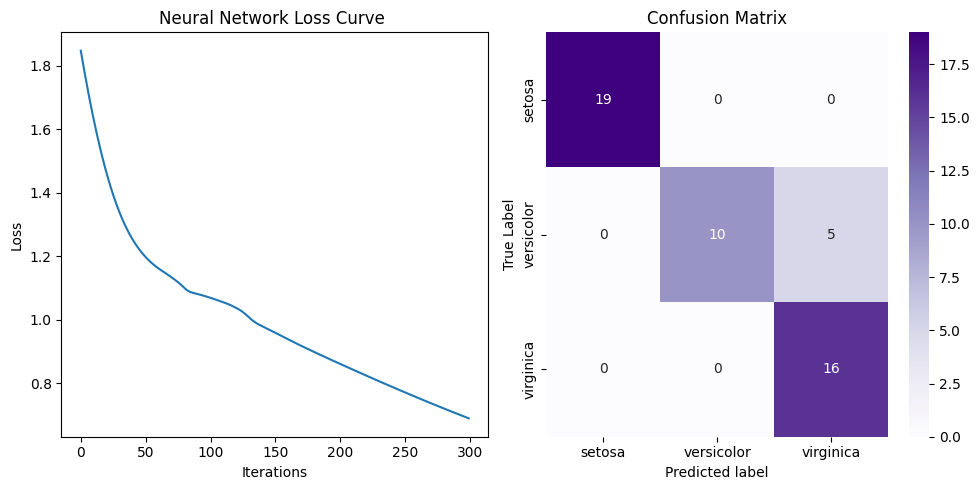

In [ ]:
#visualization

import matplotlib.pyplot as plt
import seaborn as sns


#Visulization : Loss Curve and Confusion Matrix
fig, ax= plt.subplots(1,2, figsize =(10,5))

#plot loss curve
ax[0].plot(mlp.loss_curve_)
ax[0].set_title('Neural Network Loss Curve ')
ax[0].set_xlabel('Iterations')
ax[0].set_ylabel('Loss')



#plot the confusion matrix
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot = True, cmap='Purples',xticklabels=iris.target_names,yticklabels= iris.target_names, ax=ax[1])
ax[1].set_title('Confusion Matrix')
ax[1].set_xlabel('Predicted label')
ax[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()